In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/flight_delay_data/19_20_cleaned_data.csv")
print(df.info())
print(df.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1165231 entries, 0 to 1165230
Data columns (total 15 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   DAY_OF_MONTH       1165231 non-null  int64  
 1   DAY_OF_WEEK        1165231 non-null  int64  
 2   OP_CARRIER         1165231 non-null  object 
 3   TAIL_NUM           1165231 non-null  object 
 4   OP_CARRIER_FL_NUM  1165231 non-null  int64  
 5   ORIGIN             1165231 non-null  object 
 6   DEST               1165231 non-null  object 
 7   DEP_TIME           1165231 non-null  float64
 8   DEP_DEL15          1165231 non-null  int64  
 9   DEP_TIME_BLK       1165231 non-null  object 
 10  ARR_TIME           1165231 non-null  float64
 11  ARR_DEL15          1165231 non-null  int64  
 12  DISTANCE           1165231 non-null  float64
 13  IS_WEEKEND         1165231 non-null  int64  
 14  IS_DELAYED         1165231 non-null  int64  
dtypes: float64(3), int64(7), object(

In [ ]:
df = df.drop(columns=[
    "TAIL_NUM", "OP_CARRIER_FL_NUM",
    "ORIGIN_AIRPORT_SEQ_ID", "DEST_AIRPORT_SEQ_ID"
], errors='ignore') #drop unnecessary columns

df = df.dropna(subset=["DEP_TIME", "ARR_TIME", "IS_DELAYED"]) #drop rows which miss critical data


In [ ]:
y = df["IS_DELAYED"]
X = df.drop(columns=["IS_DELAYED", "DEP_DEL15", "ARR_DEL15"])


In [ ]:
X = X.drop(columns=["ROUTE"], errors='ignore')

#encode categorical variables with one-hot encoding
X = pd.get_dummies(
    X,
    columns=["OP_CARRIER", "ORIGIN", "DEST", "DEP_TIME_BLK"],
    drop_first=True
)


In [ ]:
# Note: XGBoost doesn't require scaling (tree-based models are scale-invariant)
# This is different from logistic regression which benefits from scaling

print("Shape:", X.shape)
print("Approx memory GB:", X.memory_usage(deep=True).sum() / 1e9)


Shape: (1165231, 744)
Approx memory GB: 0.915871698


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [ ]:
# Install xgboost if not already installed
%pip install xgboost


In [ ]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Train XGBoost model
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
# Make predictions
y_pred = xgb_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.8957034417950027

Confusion Matrix:
 [[186253   1291]
 [ 23015  22488]]

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.99      0.94    187544
           1       0.95      0.49      0.65     45503

    accuracy                           0.90    233047
   macro avg       0.92      0.74      0.79    233047
weighted avg       0.90      0.90      0.88    233047



In [ ]:
# Get prediction probabilities
y_prob = xgb_model.predict_proba(X_test)[:, 1]


In [ ]:
# Feature importance
import numpy as np

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Top 20 Most Important Features:")
print(feature_importance.head(20))


Top 20 Most Important Features:
                    Feature  Importance
733  DEP_TIME_BLK_1300-1359    0.075091
731  DEP_TIME_BLK_1100-1159    0.074108
730  DEP_TIME_BLK_1000-1059    0.072889
737  DEP_TIME_BLK_1700-1759    0.064411
738  DEP_TIME_BLK_1800-1859    0.057611
729  DEP_TIME_BLK_0900-0959    0.050552
736  DEP_TIME_BLK_1600-1659    0.046100
732  DEP_TIME_BLK_1200-1259    0.044176
735  DEP_TIME_BLK_1500-1559    0.036396
734  DEP_TIME_BLK_1400-1459    0.030057
2                  DEP_TIME    0.025771
740  DEP_TIME_BLK_2000-2059    0.025735
726  DEP_TIME_BLK_0600-0659    0.024167
739  DEP_TIME_BLK_1900-1959    0.023559
728  DEP_TIME_BLK_0800-0859    0.018985
742  DEP_TIME_BLK_2200-2259    0.018152
727  DEP_TIME_BLK_0700-0759    0.017109
743  DEP_TIME_BLK_2300-2359    0.015609
741  DEP_TIME_BLK_2100-2159    0.013653
484                DEST_EWR    0.010640


Computing metrics for 201 thresholds (optimized from 216109)...


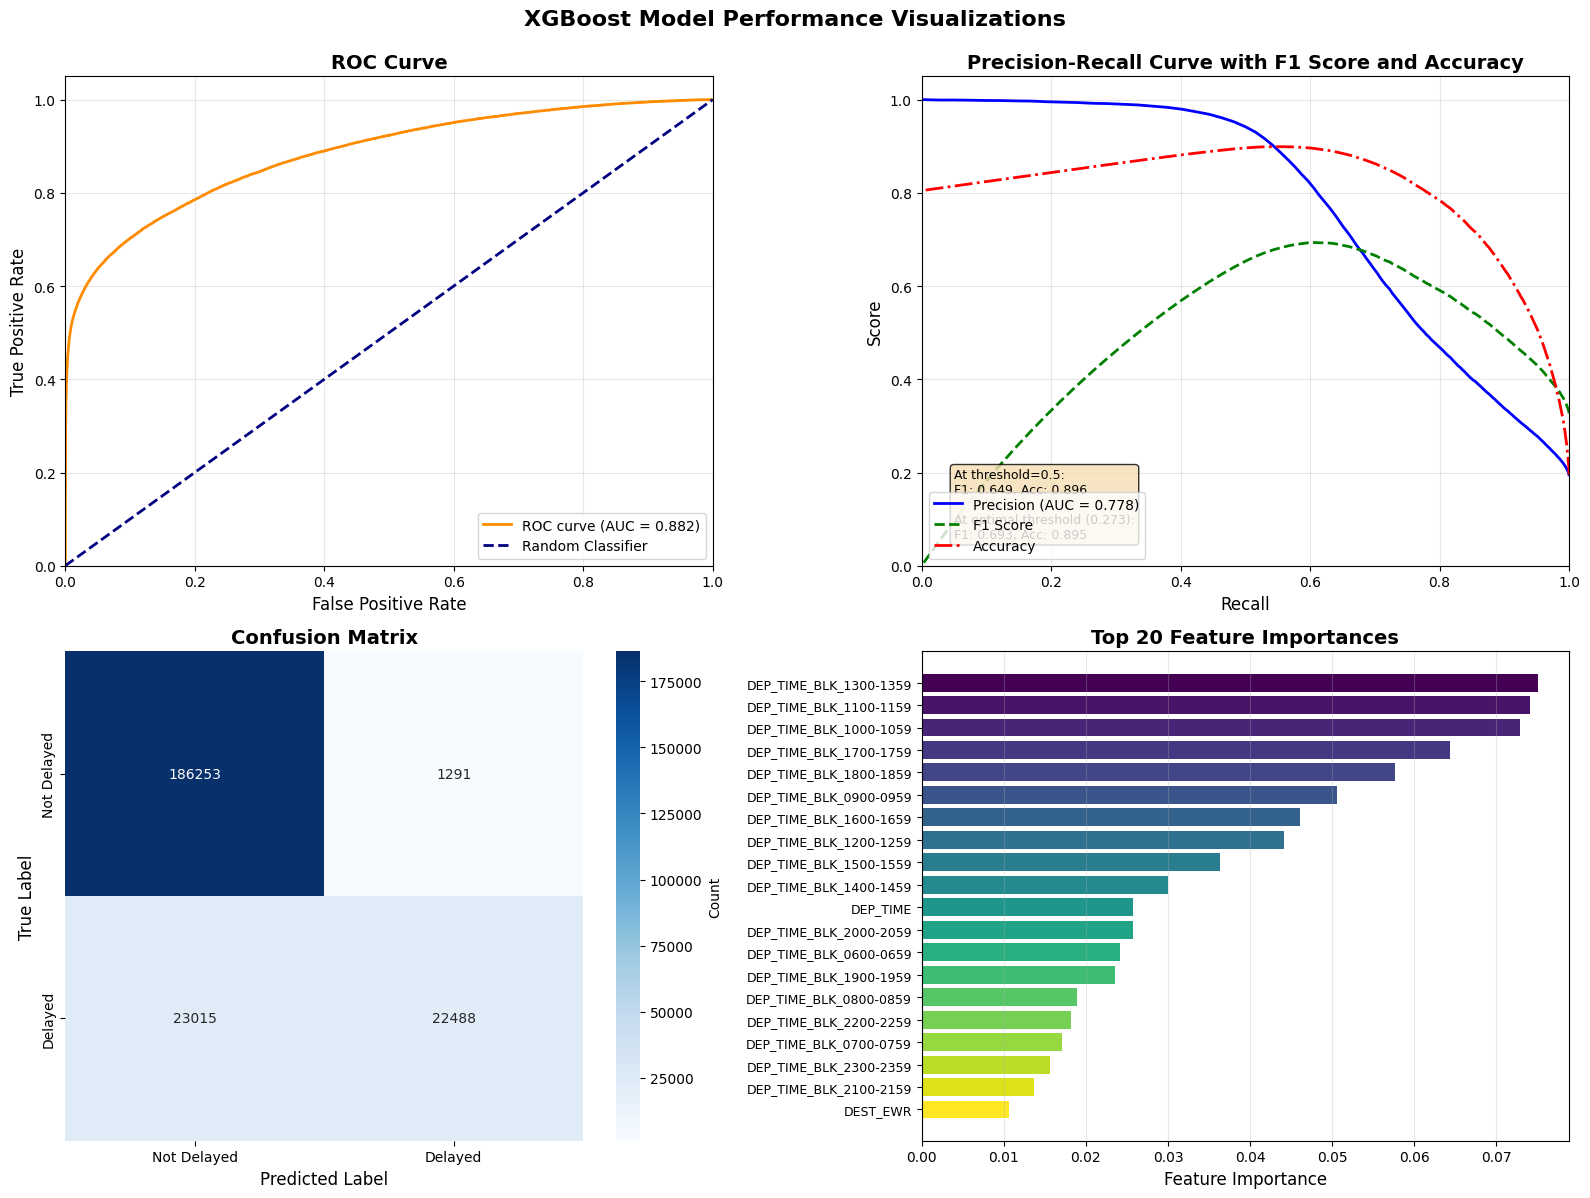


Model Performance Summary:
ROC AUC: 0.8823
PR AUC: 0.7783

At Default Threshold (0.5):
  F1 Score: 0.6492
  Accuracy: 0.8957

At Optimal Threshold (0.273):
  F1 Score: 0.6934
  Accuracy: 0.8954


In [ ]:
# Model Visualizations: ROC Curve, PR Curve, Confusion Matrix, Feature Importance
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, precision_recall_curve, roc_auc_score
import numpy as np

# Set style
plt.style.use('default')
sns.set_palette("husl")

# Create figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. ROC Curve
fpr, tpr, thresholds_roc = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

axes[0, 0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
axes[0, 0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
axes[0, 0].set_xlim([0.0, 1.0])
axes[0, 0].set_ylim([0.0, 1.05])
axes[0, 0].set_xlabel('False Positive Rate', fontsize=12)
axes[0, 0].set_ylabel('True Positive Rate', fontsize=12)
axes[0, 0].set_title('ROC Curve', fontsize=14, fontweight='bold')
axes[0, 0].legend(loc="lower right")
axes[0, 0].grid(alpha=0.3)

# 2. Precision-Recall Curve with F1 Score and Accuracy Curves
from sklearn.metrics import f1_score

precision, recall, thresholds_pr = precision_recall_curve(y_test, y_prob)
pr_auc = auc(recall, precision)

# Calculate F1 score and accuracy at default threshold (0.5)
f1_default = f1_score(y_test, y_pred)
accuracy_default = accuracy_score(y_test, y_pred)

# Calculate F1 scores and accuracy at different thresholds
# Optimize: Sample thresholds to speed up computation (use every Nth threshold or max 200 points)
# This makes computation much faster while keeping smooth curves
if len(thresholds_pr) > 200:
    # Sample every Nth threshold to get ~200 points
    step = max(1, len(thresholds_pr) // 200)
    sampled_indices = np.arange(0, len(thresholds_pr), step)
    sampled_thresholds = thresholds_pr[sampled_indices]
    sampled_recall = recall[sampled_indices]
    sampled_precision = precision[sampled_indices]
else:
    sampled_thresholds = thresholds_pr
    sampled_recall = recall
    sampled_precision = precision

f1_scores = []
accuracy_scores = []
print(f"Computing metrics for {len(sampled_thresholds)} thresholds (optimized from {len(thresholds_pr)})...")
for threshold in sampled_thresholds:
    y_pred_thresh = (y_prob >= threshold).astype(int)
    f1_scores.append(f1_score(y_test, y_pred_thresh))
    accuracy_scores.append(accuracy_score(y_test, y_pred_thresh))

# Find optimal threshold (max F1 score) from sampled thresholds
optimal_idx = np.argmax(f1_scores)
optimal_threshold = sampled_thresholds[optimal_idx]
f1_optimal = f1_scores[optimal_idx]
y_pred_optimal = (y_prob >= optimal_threshold).astype(int)
accuracy_optimal = accuracy_score(y_test, y_pred_optimal)

# Plot all curves on the same graph (x-axis: Recall, y-axis: Score)
axes[0, 1].plot(sampled_recall, sampled_precision, color='blue', lw=2, label=f'Precision (AUC = {pr_auc:.3f})', linestyle='-')
axes[0, 1].plot(sampled_recall, f1_scores, color='green', lw=2, label='F1 Score', linestyle='--')
axes[0, 1].plot(sampled_recall, accuracy_scores, color='red', lw=2, label='Accuracy', linestyle='-.')
axes[0, 1].set_xlabel('Recall', fontsize=12)
axes[0, 1].set_ylabel('Score', fontsize=12)
axes[0, 1].set_title('Precision-Recall Curve with F1 Score and Accuracy', fontsize=14, fontweight='bold')
axes[0, 1].legend(loc="lower left", fontsize=10)
axes[0, 1].grid(alpha=0.3)
axes[0, 1].set_xlim([0.0, 1.0])
axes[0, 1].set_ylim([0.0, 1.05])

# Add text box with F1 score and accuracy at key thresholds
textstr = f'At threshold=0.5:\nF1: {f1_default:.3f}, Acc: {accuracy_default:.3f}\n\nAt optimal threshold ({optimal_threshold:.3f}):\nF1: {f1_optimal:.3f}, Acc: {accuracy_optimal:.3f}'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
axes[0, 1].text(0.05, 0.05, textstr, transform=axes[0, 1].transAxes, fontsize=9,
                verticalalignment='bottom', bbox=props)

# 3. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Delayed', 'Delayed'],
            yticklabels=['Not Delayed', 'Delayed'],
            cbar_kws={'label': 'Count'},
            ax=axes[1, 0])
axes[1, 0].set_ylabel('True Label', fontsize=12)
axes[1, 0].set_xlabel('Predicted Label', fontsize=12)
axes[1, 0].set_title('Confusion Matrix', fontsize=14, fontweight='bold')

# 4. Feature Importance (Top 20)
top_20 = feature_importance.head(20)
colors = plt.cm.viridis(np.linspace(0, 1, len(top_20)))
axes[1, 1].barh(range(len(top_20)), top_20['Importance'].values, color=colors)
axes[1, 1].set_yticks(range(len(top_20)))
axes[1, 1].set_yticklabels(top_20['Feature'].values, fontsize=9)
axes[1, 1].set_xlabel('Feature Importance', fontsize=12)
axes[1, 1].set_title('Top 20 Feature Importances', fontsize=14, fontweight='bold')
axes[1, 1].invert_yaxis()
axes[1, 1].grid(axis='x', alpha=0.3)

plt.suptitle('XGBoost Model Performance Visualizations', fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

print(f"\nModel Performance Summary:")
print(f"ROC AUC: {roc_auc:.4f}")
print(f"PR AUC: {pr_auc:.4f}")
print(f"\nAt Default Threshold (0.5):")
print(f"  F1 Score: {f1_default:.4f}")
print(f"  Accuracy: {accuracy_default:.4f}")
print(f"\nAt Optimal Threshold ({optimal_threshold:.3f}):")
print(f"  F1 Score: {f1_optimal:.4f}")
print(f"  Accuracy: {accuracy_optimal:.4f}")


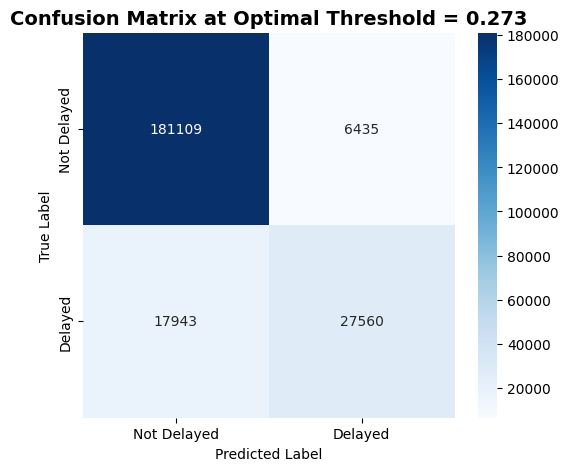

Performance at Optimal Threshold


,Metric,Value
0,Threshold,0.2728
1,F1 Score,0.6934
2,Precision,0.8107
3,Recall,0.6057
4,Accuracy,0.8954


In [ ]:
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Predict using optimal threshold ---
y_pred_opt = (y_prob >= optimal_threshold).astype(int)

# --- 2. Compute metrics ---
f1_opt = f1_score(y_test, y_pred_opt)
precision_opt = precision_score(y_test, y_pred_opt)
recall_opt = recall_score(y_test, y_pred_opt)
accuracy_opt = accuracy_score(y_test, y_pred_opt)

# --- 3. Confusion Matrix ---
cm_opt = confusion_matrix(y_test, y_pred_opt)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm_opt,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Delayed', 'Delayed'],
    yticklabels=['Not Delayed', 'Delayed']
)
plt.title(f'Confusion Matrix at Optimal Threshold = {optimal_threshold:.3f}', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# --- 4. Print schema of metrics ---
import pandas as pd

schema = pd.DataFrame({
    'Metric': ['Threshold', 'F1 Score', 'Precision', 'Recall', 'Accuracy'],
    'Value': [optimal_threshold, f1_opt, precision_opt, recall_opt, accuracy_opt]
})

print("Performance at Optimal Threshold")
display(schema.style.format({'Value': '{:.4f}'}))
